In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# load dataset yang 100% bersih
df = pd.read_csv("../data/processed/ipg_jateng_clean.csv")

# Set tema visualisasi agar lebih menarik
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Data siap dianalisis!")
display(df.head(3))

Data siap dianalisis!


,Kabupaten/Kota,IPG,IPM,IPM Laki-laki,IPM Perempuan
0,Cilacap,88.22,73.45,78.25,69.03
1,Banyumas,90.01,75.44,79.34,71.41
2,Purbalingga,94.34,71.71,75.11,70.86


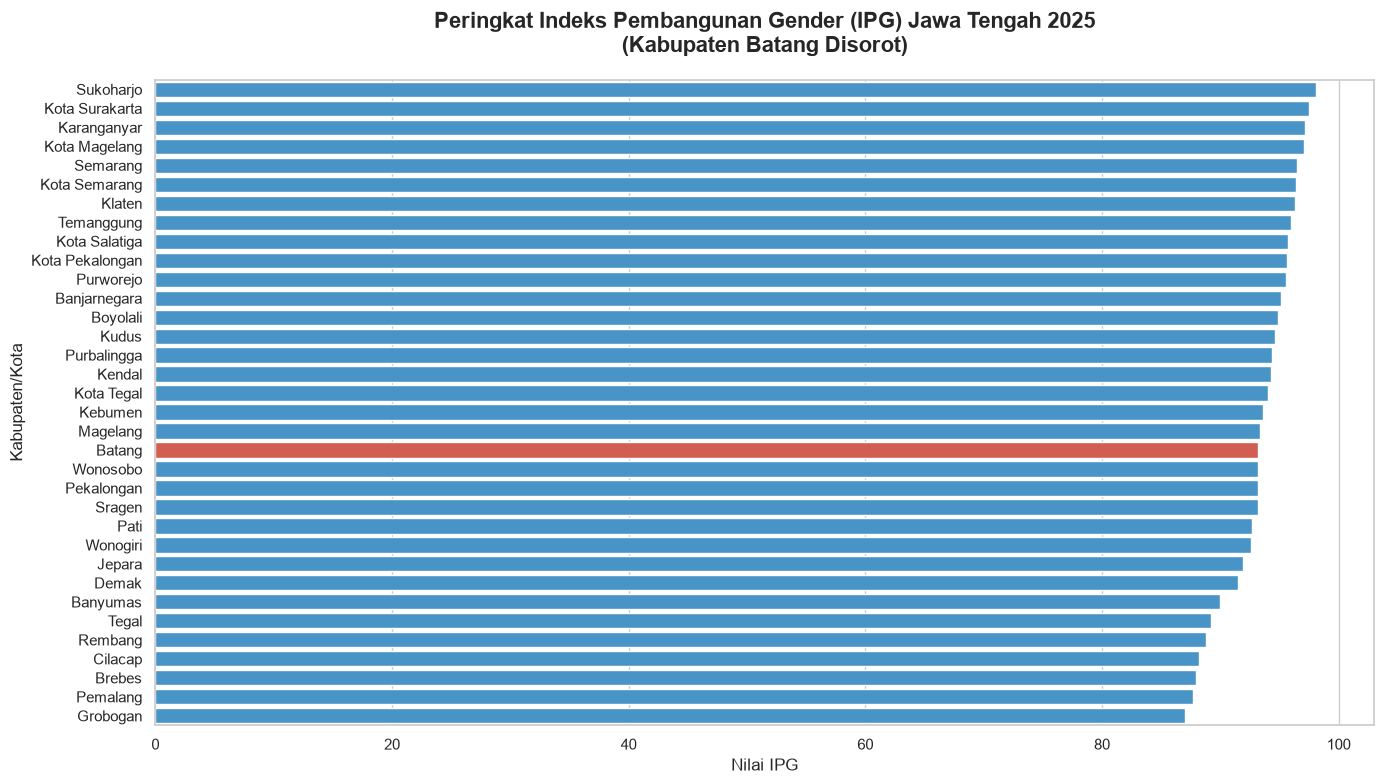

In [7]:
# 1. Urutkan data berdasarkan IPG dari yang tertinggi ke terendah
df_sorted = df.sort_values(by='IPG', ascending=False).reset_index(drop=True)

# 2. Tentukan warna: Merah/Hitam untuk Batang, Biru untuk yang lain
warna = ['#e74c3c' if kota == 'Batang' else '#3498db' for kota in df_sorted['Kabupaten/Kota']]

# 3. Buat grafik
plt.figure(figsize=(14, 8))
sns.barplot(x='IPG', y="Kabupaten/Kota", data=df_sorted, palette=warna, hue='Kabupaten/Kota', legend=False)

# 4. Tambahkan judul dan label
plt.title('Peringkat Indeks Pembangunan Gender (IPG) Jawa Tengah 2025\n(Kabupaten Batang Disorot)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Nilai IPG", fontsize=12)
plt.ylabel("Kabupaten/Kota", fontsize=12)

# 5. Menampilkan grafik
plt.tight_layout()
plt.show()

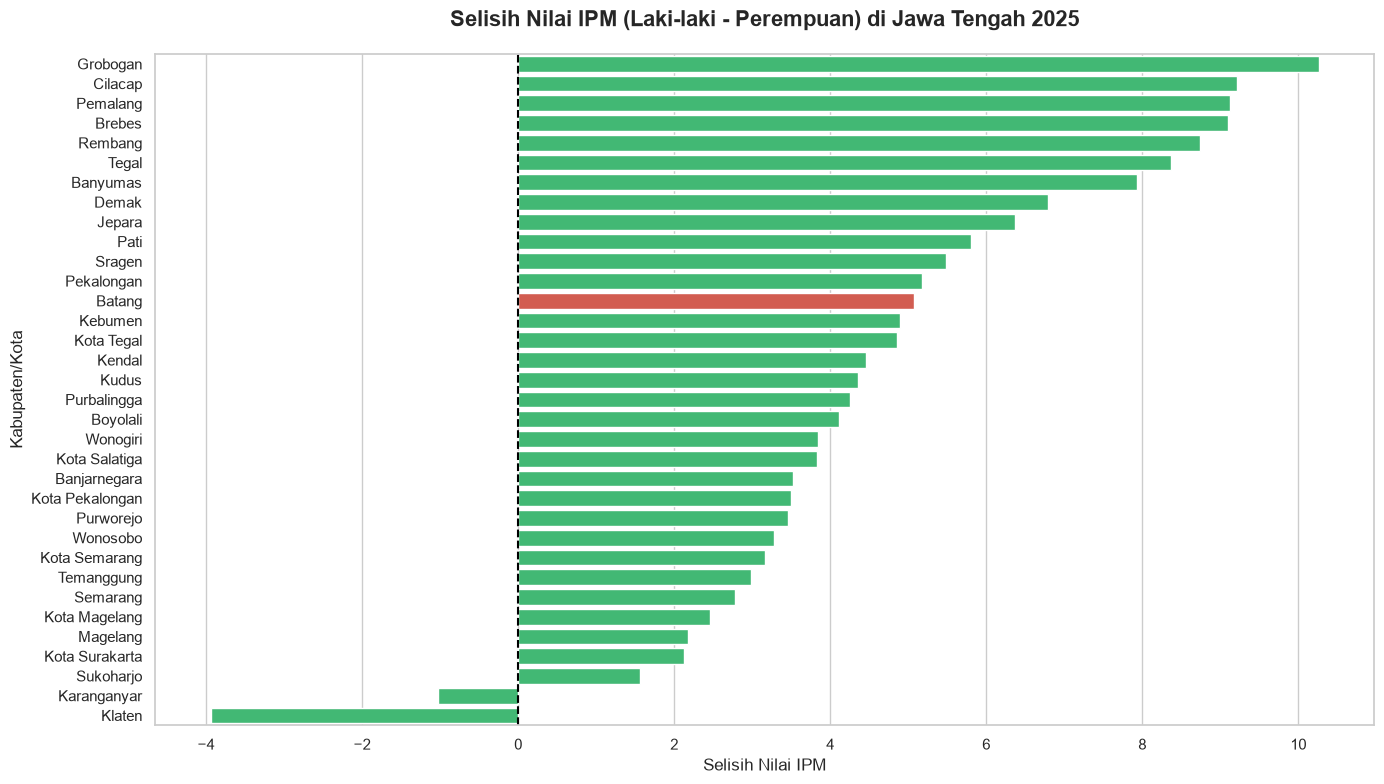

In [11]:
# 1. Hitung selisih IPM Laki-laki dan Perempuan
df['Selisih_IPM'] = df['IPM Laki-laki'] - df['IPM Perempuan']

# 2. Urutkan berdasarkan selisih terbesar
df_gap = df.sort_values(by='Selisih_IPM', ascending=False)

# 3. Buat grafik
plt.figure(figsize=(14, 8))
warna_gap = ['#e74c3c' if kota == 'Batang' else '#2ecc71' for kota in df_gap['Kabupaten/Kota']]
sns.barplot(x='Selisih_IPM', y='Kabupaten/Kota', data=df_gap, palette=warna_gap, hue='Kabupaten/Kota', legend=False)

plt.title('Selisih Nilai IPM (Laki-laki - Perempuan) di Jawa Tengah 2025', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Selisih Nilai IPM', fontsize=12)
plt.ylabel('Kabupaten/Kota', fontsize=12)
plt.axvline(x=0, color='black', linestyle='--') # <-- garis nol

plt.tight_layout()
plt.show()